# NB-11-01 — Tokens, Attention and Generative Models

This workbench accompanies L11-01 and L11-02. Every number printed here comes from the
module's own code on your machine; the tests are deterministic (fixed seeds, greedy decoding)
so the values should match the lessons to the printed precision.

Run the cells in order. The first model load takes longer than the rest.

In [1]:
# Make the module's reference code importable from the notebooks/ directory.
import sys, pathlib
CODE_DIR = None
for _base in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
    if (_base / "code").is_dir() and (_base / "notebooks").is_dir():
        CODE_DIR = _base / "code"
        break
if CODE_DIR is None:
    CODE_DIR = pathlib.Path.cwd().parent / "code"
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))
print("code on path:", CODE_DIR)


code on path: C:\Users\Nadeem\Documents\Artificial-Intelligence-Course\modules\M11-generative-ai-and-large-language-models\code


In [2]:
import sys, time
sys.path.insert(0, ".")

import numpy as np
import matplotlib.pyplot as plt

from gen_data import HANDBOOK
texts = [d["text"] for d in HANDBOOK.values()]
print("documents:", len(texts))
print("words:", sum(len(t.split()) for t in texts))
print("characters:", sum(len(t) for t in texts))

documents: 24
words: 1895
characters: 11608


## 1. Tokenisation

BPE learns merges from the corpus. Eighteen merges on a 37-symbol base alphabet produce a
55-symbol vocabulary — a toy version of what a real tokeniser does 50,000 times.

In [3]:
from tokenizers_lab import learn_bpe, apply_bpe, bpe_vocab_size, compare_granularities, token_report

merges, history = learn_bpe(texts, num_merges=12)
print("merges learned:", len(merges), "vocab:", bpe_vocab_size(merges, 37))
for w in ("library", "students", "mitigating"):
    print(f"{w:12s} -> {apply_bpe(w, merges)}")

s = "Northfield University charges 9,250 GBP for undergraduate tuition."
g = compare_granularities(s)
print({k: g[k] for k in ("characters", "words", "subword_tokens", "chars_per_token")})
print(g["subword_pieces"])

rep = token_report(texts)
print({k: rep[k] for k in ("tokens", "chars_per_token", "tokens_per_word", "vocab_used")})

merges learned: 12 vocab: 49
library      -> ['l', 'i', 'b', 'r', 'a', 'r', 'y', '</w>']
students     -> ['s', 't', 'u', 'd', 'en', 't', 's</w>']
mitigating   -> ['m', 'i', 't', 'i', 'g', 'a', 't', 'in', 'g', '</w>']


C:\Users\Nadeem\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'characters': 66, 'words': 8, 'subword_tokens': 13, 'chars_per_token': 5.076923076923077}
['North', 'field', ' University', ' charges', ' 9', ',', '250', ' GB', 'P', ' for', ' undergraduate', ' tuition', '.']


{'tokens': 2281, 'chars_per_token': 5.088996054362122, 'tokens_per_word': 1.203693931398417, 'vocab_used': 871}


## 2. Attention by hand

The scaled dot-product formula, one head, every intermediate value printed. Note that the
softmax weights are never one-hot — that softness is what makes attention differentiable.

In [4]:
from attention_lab import (scaled_dot_product_attention, causal_mask, softmax_saturation,
                           multi_head_attention, sinusoidal_positions)

q = np.array([[1.0, 0.0]]); k = np.eye(2); v = np.array([[10.0, 0.0], [0.0, 20.0]])
out, w, scores = scaled_dot_product_attention(q, k, v, return_weights=True)
print("scores", scores, "weights", w, "output", out)

print(causal_mask(4))
for d_k in (4, 64, 256):
    r = softmax_saturation(d_k)
    print(f"d_k={d_k:4d} raw max {r['raw_max_weight']:.4f} entropy {r['raw_entropy']:.4f}"
          f" | scaled max {r['scaled_max_weight']:.4f} entropy {r['scaled_entropy']:.4f}")

pe = sinusoidal_positions(8, 16)
print(pe[:3, :6].round(3))

scores [[0.707 0.   ]] weights [[0.67 0.33]] output [[6.698 6.605]]
[[ 0.e+00 -1.e+09 -1.e+09 -1.e+09]
 [ 0.e+00  0.e+00 -1.e+09 -1.e+09]
 [ 0.e+00  0.e+00  0.e+00 -1.e+09]
 [ 0.e+00  0.e+00  0.e+00  0.e+00]]
d_k=   4 raw max 0.2049 entropy 2.1344 | scaled max 0.1497 entropy 2.2557
d_k=  64 raw max 0.9297 entropy 0.2608 | scaled max 0.3075 entropy 1.9633
d_k= 256 raw max 1.0000 entropy 0.0000 | scaled max 0.5815 entropy 1.5017
[[ 0.     1.     0.     1.     0.     1.   ]
 [ 0.841  0.54   0.311  0.95   0.1    0.995]
 [ 0.909 -0.416  0.591  0.807  0.199  0.98 ]]


## 3. What a pretrained model's heads do

distilgpt2 has 6 layers and 12 heads. On a 13-token sentence, attention sharpens with depth
and looks further back — measured, not assumed.

In [5]:
from attention_lab import attention_profile, next_token_report

prof = attention_profile("The library opens at eight and closes at eleven on weekdays.")
print("tokens:", prof["tokens"])
for L in prof["layers"]:
    print(f"layer {L['layer']}  entropy {L['mean_entropy']:.3f}  "
          f"self {L['self_mass']:.3f}  lookback {L['mean_distance']:.3f}")

for row in next_token_report("The library opens at")[:3]:
    print(f"  {row['token']!r:10s} p={row['p']:.4f}")

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Loading weights:  30%|███       | 23/76 [00:00<00:00, 179.98it/s]

Loading weights:  54%|█████▍    | 41/76 [00:00<00:00, 86.88it/s] 

Loading weights: 100%|██████████| 76/76 [00:00<00:00, 173.67it/s]

tokens: 13
layer 0  entropy 1.180  self 0.386  lookback 2.618
layer 1  entropy 1.117  self 0.163  lookback 3.324
layer 2  entropy 0.859  self 0.166  lookback 3.668
layer 3  entropy 0.744  self 0.116  lookback 4.739
layer 4  entropy 0.644  self 0.110  lookback 5.202
layer 5  entropy 0.774  self 0.132  lookback 4.975


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Loading weights:  11%|█         | 8/76 [00:00<00:01, 50.08it/s]

Loading weights: 100%|██████████| 76/76 [00:00<00:00, 426.57it/s]

  ' the'     p=0.1565
  ' 10'      p=0.0536
  ' 7'       p=0.0510


## 4. Three generative families, one metric

`gen_models.py` trained a VAE, a GAN and a diffusion model on the same 1,797 8×8 digits. The
differences below are the lesson: the GAN's loss looked fine while it covered three classes.

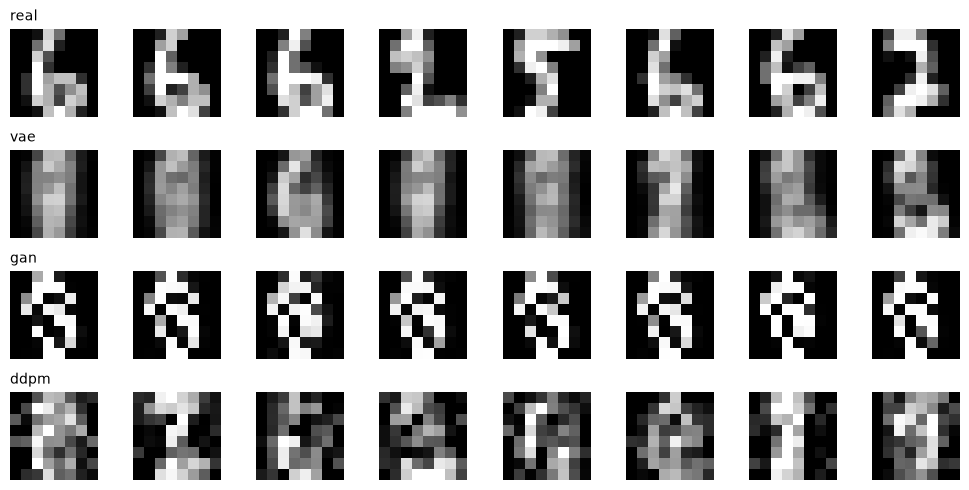

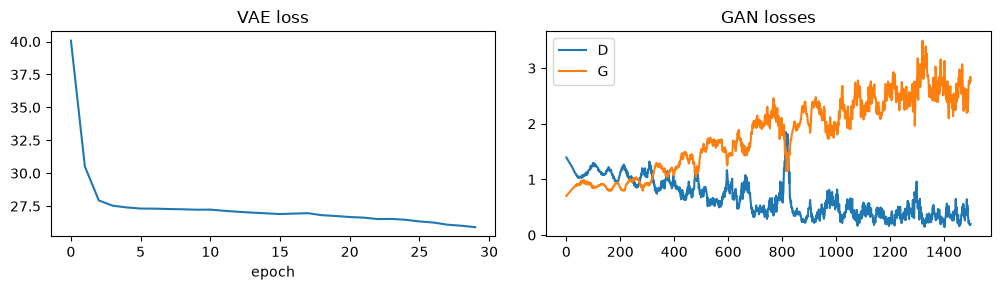

ddpm first/last 100 mean: 0.5604 0.2168


In [6]:
data = np.load(CODE_DIR / "gen_samples.npz")
fig, axes = plt.subplots(4, 8, figsize=(10, 5))
for row, name in enumerate(["real", "vae", "gan", "ddpm"]):
    for col in range(8):
        axes[row, col].imshow(data[name][col].reshape(8, 8), cmap="gray", vmin=0, vmax=1)
        axes[row, col].axis("off")
    axes[row, 0].set_title(name, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(data["vae_loss"]); ax[0].set_title("VAE loss"); ax[0].set_xlabel("epoch")
ax[1].plot(data["gan_d"], label="D"); ax[1].plot(data["gan_g"], label="G")
ax[1].set_title("GAN losses"); ax[1].legend()
plt.tight_layout(); plt.show()
print("ddpm first/last 100 mean:", data["ddpm_loss"][:100].mean().round(4),
      data["ddpm_loss"][-100:].mean().round(4))

## 5. Decoding is a policy

The same model and prompt, seven decoding strategies. Greedy collapses to newlines here;
nucleus sampling with a temperature and a repetition penalty is the only varied output.

In [7]:
from llm_gen import sample_text, perplexity

configs = [("greedy", dict(greedy=True)), ("T 0.7", dict(temperature=0.7)),
           ("T 1.0", dict(temperature=1.0)), ("top-p 0.9", dict(top_p=0.9)),
           ("top-k 40", dict(top_k=40))]
for name, kw in configs:
    r = sample_text("The library opens at", **kw)
    print(f"{name:12s} entropy {r['mean_entropy']:.3f} distinct2 {r['distinct_2']:.2f} "
          f"rep {r['repetition_rate']:.2f} -> {r['text'][:38]!r}")

print(perplexity("The wellbeing service offers free, confidential counselling."))

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 76/76 [00:00<00:00, 4923.04it/s]

greedy       entropy -0.000 distinct2 0.30 rep 0.20 -> ' the end of the day.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n'


T 0.7        entropy 0.685 distinct2 0.22 rep 0.00 -> ' a new time.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n'


T 1.0        entropy 3.630 distinct2 1.00 rep 0.17 -> ' a button seven times a second...'


top-p 0.9    entropy 0.766 distinct2 0.17 rep 0.00 -> ' a button:\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n'


top-k 40     entropy 1.985 distinct2 0.85 rep 0.00 -> ' a new time.\n\n\n\n\nA full list of my fav'
{'tokens': 9, 'nll_per_token': 5.5193108446689605, 'perplexity': 249.46305913960182}


## Exercises

1. Change `num_merges` to 40 and report the vocabulary size and how `mitigating` splits.
2. Compute attention with `d_k=16` and a 2-key example by hand, then verify in code.
3. Train the VAE with `beta=4.0` and compare sample diversity with `beta=1.0`.
4. Find a prompt where greedy decoding is *better* than sampled decoding, and explain why.